# Klasterisasi Akses Air Bersih

## Model Klasterisasi dengan Algoritma K-Means

### 1. Mengimpor library

In [1]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

### 2. Set Working Directory

In [2]:
os.chdir(r'C:\Users\Sulthon Kamel M\Documents\S2\Perkuliahan\SIKC\Analitika Perkotaan\11 Pengembangan Model Klasterisasi\1649038549979_Hands-on-Clustering')
# Print the current working directory
print("Current working directory: {0}".format(os.getcwd()))

Current working directory: C:\Users\Sulthon Kamel M\Documents\S2\Perkuliahan\SIKC\Analitika Perkotaan\11 Pengembangan Model Klasterisasi\1649038549979_Hands-on-Clustering


### 3. Mengimpor Dataset

In [3]:
dataset = pd.read_csv('KMeans.csv')
X = dataset.iloc[:, [2,4]].values

### 4. Menentukan nilai K dengan menggunakan metode _elbow_

C:\Users\Sulthon Kamel M\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


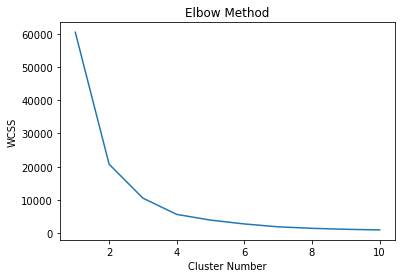

In [4]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title('Elbow Method')
plt.xlabel('Cluster Number')
plt.ylabel('WCSS')
plt.show()

### 5. Menjalankan K-Means Clustering ke dataset

In [5]:
kmeans = KMeans(n_clusters = 5, init = 'k-means++', random_state = 42)
y_kmeans = kmeans.fit_predict(X)

### 6. Visualisasi hasil clusters

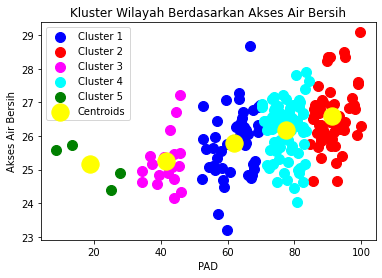

In [6]:
plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s = 100, c = 'blue', label = 'Cluster 1')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s = 100, c = 'red', label = 'Cluster 2')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s = 100, c = 'magenta', label = 'Cluster 3')
plt.scatter(X[y_kmeans == 3, 0], X[y_kmeans == 3, 1], s = 100, c = 'cyan', label = 'Cluster 4')
plt.scatter(X[y_kmeans == 4, 0], X[y_kmeans == 4, 1], s = 100, c = 'green', label = 'Cluster 5')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s = 300, c = 'yellow', label = 'Centroids')
plt.title('Kluster Wilayah Berdasarkan Akses Air Bersih')
plt.xlabel('PAD')
plt.ylabel('Akses Air Bersih')
plt.legend()
plt.show()

## Model Klasterisasi dengan Algoritma Hierarchical Clustering

### 1. Mengimpor library

In [7]:
import scipy.cluster.hierarchy as sch #Library untuk analysis dendogram
from sklearn.cluster import AgglomerativeClustering #Library untuk HC

### 2. Menggunakan dendrogram untuk menentukan angka cluster yang tepat

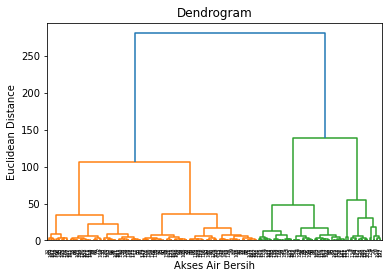

In [8]:
dendrogram = sch.dendrogram(sch.linkage(X, method = 'ward'))
plt.title('Dendrogram')
plt.xlabel('Akses Air Bersih')
plt.ylabel('Euclidean Distance')
plt.show()

### 3. Menjalankan Hierarchical Clustering ke dataset

In [9]:
# Menjalankan Hierarchical Clustering ke dataset
hc = AgglomerativeClustering(n_clusters = 5, affinity = 'euclidean', linkage = 'ward')
y_hc = hc.fit_predict(X)

### 4. Visualisasi hasil clusters

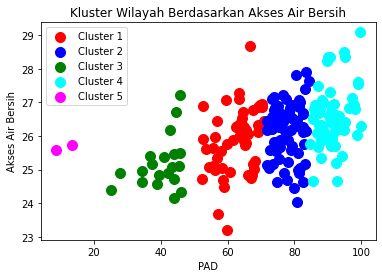

In [10]:
plt.scatter(X[y_hc == 0, 0], X[y_hc == 0, 1], s = 100, c = 'red', label = 'Cluster 1')
plt.scatter(X[y_hc == 1, 0], X[y_hc == 1, 1], s = 100, c = 'blue', label = 'Cluster 2')
plt.scatter(X[y_hc == 2, 0], X[y_hc == 2, 1], s = 100, c = 'green', label = 'Cluster 3')
plt.scatter(X[y_hc == 3, 0], X[y_hc == 3, 1], s = 100, c = 'cyan', label = 'Cluster 4')
plt.scatter(X[y_hc == 4, 0], X[y_hc == 4, 1], s = 100, c = 'magenta', label = 'Cluster 5')
plt.title('Kluster Wilayah Berdasarkan Akses Air Bersih')
plt.xlabel('PAD')
plt.ylabel('Akses Air Bersih')
plt.legend()
plt.show()

## Model Klasterisasi dengan Algoritma DBSCAN

### 1. Mengimpor library

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.datasets import make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

### 2. Membuat dataset 

In [12]:
X, y = make_circles(n_samples=750, factor=0.3, noise=0.1)
X = StandardScaler().fit_transform(X)

### 3. Menjalankan DBScan

In [13]:
y_pred = DBSCAN(eps=0.4, min_samples=10).fit_predict(X)

### 4. Lakukan visualisasi

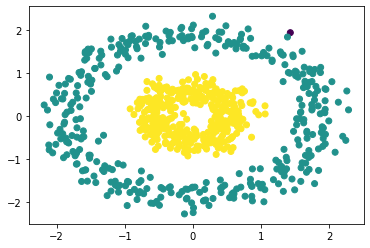

In [14]:
plt.scatter(X[:,0], X[:,1], c=y_pred)

### 5. Hitung performa cluster

In [15]:
print('Number of clusters: {}'.format(len(set(y_pred[np.where(y_pred != -1)]))))
print('Homogeneity: {}'.format(metrics.homogeneity_score(y, y_pred)))
print('Completeness: {}'.format(metrics.completeness_score(y, y_pred)))
print("Adjusted Rand Index: %0.3f"
      % metrics.adjusted_rand_score(y,y_pred))
print("Adjusted Mutual Information: %0.3f"
      % metrics.adjusted_mutual_info_score(y, y_pred))
print("Silhouette Coefficient: %0.3f"
      % metrics.silhouette_score(X, y_pred))

Number of clusters: 2
Homogeneity: 1.0
Completeness: 0.9868531209841904
Adjusted Rand Index: 0.997
Adjusted Mutual Information: 0.993
Silhouette Coefficient: 0.139


## Model Klasterisasi dengan Algoritma DBSCAN dengan Spherical Data

### 1. Impor library

In [16]:
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn import metrics
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

### 2. Generate sample data

In [17]:
centers = [[1, 1], [-1, -1], [1, -1]]
X, labels_true = make_blobs(n_samples=500, centers=centers, cluster_std=0.4,
                            random_state=0)

X = StandardScaler().fit_transform(X)

### 3. Menghitung DBSCAN

In [18]:
db = DBSCAN(eps=0.3, min_samples=10).fit(X)
core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
labels = db.labels_

### 4. Menentukan jumlah klaster pada label dengan mengabaikan noise

In [19]:
# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

### 5. Lakukan visualisasi

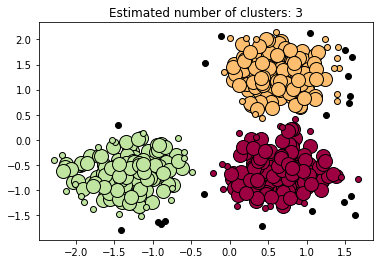

In [20]:
# Black removed and is used for noise instead.
unique_labels = set(labels)
colors = [plt.cm.Spectral(each)
          for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=14)

    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=6)
    
plt.title('Estimated number of clusters: %d' % n_clusters_)
plt.show()

### 6. Menghitung kinerja cluster

In [21]:
print('Estimated number of noise points: %d' % n_noise_)
print("Homogeneity: %0.3f" % metrics.homogeneity_score(labels_true, labels))
print("Completeness: %0.3f" % metrics.completeness_score(labels_true, labels))
print("V-measure: %0.3f" % metrics.v_measure_score(labels_true, labels))
print("Adjusted Rand Index: %0.3f"
      % metrics.adjusted_rand_score(labels_true, labels))
print("Adjusted Mutual Information: %0.3f"
      % metrics.adjusted_mutual_info_score(labels_true, labels))
print("Silhouette Coefficient: %0.3f"
      % metrics.silhouette_score(X, labels))

Estimated number of noise points: 20
Homogeneity: 0.939
Completeness: 0.844
V-measure: 0.889
Adjusted Rand Index: 0.927
Adjusted Mutual Information: 0.888
Silhouette Coefficient: 0.605
